# MovieLens ALS — Embedding and Recommendation Analysis

**Purpose.** Examine the fitted movie representations and the recommendations produced by the **Bias-Only** and **Bias + Factors** ALS models. This notebook is an analysis companion to `src/main.py`: it **does not download data, split ratings, tune hyperparameters, or train a model**.

**Questions explored**

1. Which movies are nearest to a chosen movie in the *original* learned embedding space?
2. Do related movies appear near one another in PCA and t-SNE visualizations?
3. How do recommendations change with a new user's movie ratings, model choice, or movie-bias ranking weight?

**Before running:** Train your models with `python -m src.main --model both --dataset ml-latest-small` (or choose another dataset), then set `DATASET_NAME` in the next cell.

## 1. Configuration and saved artifacts

The notebook reads the same ID mappings and model files that `main.py` saved. It uses **original MovieLens IDs** to select movies and **internal zero-based indices** to retrieve their learned factors. To study a different experiment, change only `DATASET_NAME` (and retrain that dataset beforehand).

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# ---------------------- Reviewer settings ----------------------
DATASET_NAME = "ml-32m"            # Alternatively, "ml-latest-small"
SEED = 42
TOP_N = 10
PCA_BACKGROUND = 1500              # Background movie points to display
TSNE_BACKGROUND = 350              # Other movies fitted alongside chosen movies
# ---------------------------------------------------------------


# Support running the notebook from either the repository root or notebooks/.
CWD = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (CWD, CWD.parent) if (p / "src" / "main.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open JupyterLab in the project root or its notebooks/ directory."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import utils

DATA_DIR = PROJECT_ROOT / "data"
EXPERIMENT_DIR = PROJECT_ROOT / "experiments"
PREPROCESS_DIR = DATA_DIR / DATASET_NAME / "preprocess"
MODEL_DIR = EXPERIMENT_DIR / DATASET_NAME / "model_files"
ANALYSIS_DIR = EXPERIMENT_DIR / DATASET_NAME / "images" / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", PROJECT_ROOT)
print("Dataset:", DATASET_NAME)
print("Figures saved under:", ANALYSIS_DIR)

Repository: /Users/ayanful/Library/CloudStorage/GoogleDrive-emmanuelayanful@u.boisestate.edu/My Drive/Academic Work/Research/CompExamFolder/Code Repo/Movie-Recommendation-System
Dataset: ml-32m
Figures saved under: /Users/ayanful/Library/CloudStorage/GoogleDrive-emmanuelayanful@u.boisestate.edu/My Drive/Academic Work/Research/CompExamFolder/Code Repo/Movie-Recommendation-System/experiments/ml-32m/images/analysis


In [2]:
# Load only what analysis requires: never reload the full ratings or split arrays.
required_files = [
    PREPROCESS_DIR / "map_movie_to_id.pkl",
    PREPROCESS_DIR / "map_id_to_movie.pkl",
    PREPROCESS_DIR / "map_movie_to_title.pkl",
    MODEL_DIR / "movie_embeddings.npy",
    MODEL_DIR / "movie_biases.npy",
]
missing = [str(path) for path in required_files if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing saved artifacts. Run src/main.py for this dataset first:\n"
        + "\n".join(missing)
    )

movie_to_index = utils.load_data_from_pickle(PREPROCESS_DIR, "map_movie_to_id", log=False)
index_to_movie = utils.load_data_from_pickle(PREPROCESS_DIR, "map_id_to_movie", log=False)
movie_to_title = utils.load_data_from_pickle(PREPROCESS_DIR, "map_movie_to_title", log=False)
movie_factors = utils.load_numpy_array(MODEL_DIR, "movie_embeddings", log=False)
movie_biases = utils.load_numpy_array(MODEL_DIR, "movie_biases", log=False).reshape(-1)

n_movies, n_factors = movie_factors.shape
if n_movies != len(movie_to_index) or len(movie_biases) != n_movies:
    raise ValueError("Movie mappings and factor-model arrays have different lengths.")
if any(movie_to_index[index_to_movie[i]] != i for i in range(n_movies)):
    raise ValueError("MovieLens IDs do not agree with the saved internal index mapping.")
if not np.isfinite(movie_factors).all() or not np.isfinite(movie_biases).all():
    raise ValueError("Non-finite parameters found in saved movie arrays.")

# Movies with zero factor vectors (e.g., unseen in training) are not useful for
# cosine-similarity exploration.
factor_norms = np.linalg.norm(movie_factors, axis=1)
valid_factors = factor_norms > 1e-12
unit_factors = np.zeros_like(movie_factors, dtype=float)
unit_factors[valid_factors] = movie_factors[valid_factors] / factor_norms[valid_factors, None]

bias_path = MODEL_DIR / "movie_biases_b.npy"
bias_movie_factors = (
    utils.load_numpy_array(MODEL_DIR, "movie_biases_b", log=False).reshape(-1)
    if bias_path.is_file() else None
)
if bias_movie_factors is not None and len(bias_movie_factors) != n_movies:
    raise ValueError("Bias-Only movie biases do not match the movie index mapping.")


# Read summaries separately; they are the record of parameters used for these weights.
def optional_training_summary(name: str):
    path = MODEL_DIR / f"training_summary_{name}.json"
    return json.loads(path.read_text(encoding="utf-8")) if path.is_file() else None


factor_summary = optional_training_summary("bias_factors")
bias_summary = optional_training_summary("bias")

print(f"Movies represented in model: {n_movies:,}")
print(f"Latent dimensions: {n_factors}")
print(f"Movies with nonzero factors: {np.count_nonzero(valid_factors):,}")
print(f"Bias-Only weights available: {bias_movie_factors is not None}")
print(f"Factor training summary available: {factor_summary is not None}")

Movies represented in model: 84,432
Latent dimensions: 16
Movies with nonzero factors: 80,114
Bias-Only weights available: True
Factor training summary available: True


### Model configurations used in this analysis

Saved `training_summary_bias.json` and `training_summary_bias_factors.json` are produced by the current `main.py`. Their hyperparameters must correspond to the actual weight files being loaded. We **do not** use a new Optuna study to obtain parameters for this notebook.

In [3]:
rows = []
for name, summary in (("Bias-Only", bias_summary), ("Bias + Factors", factor_summary)):
    if summary is not None:
        params = summary["hyperparameters"]
        rows.append({
            "Model": name,
            "Epochs": summary["n_epochs"],
            "Factors": summary.get("n_factors") or "—",
            "lambda_reg": params["lambda_reg"],
            "gamma": params["gamma"],
            "tau": params.get("tau", np.nan),
            "Train RMSE": summary["train_rmse"],
            "Test RMSE": summary["test_rmse"],
        })
if rows:
    display(pd.DataFrame(rows))
else:
    print("Training summaries were not found. Embedding analysis can continue, but")
    print("new-user recommendations require the hyperparameters saved by main.py.")

,Model,Epochs,Factors,lambda_reg,gamma,tau,Train RMSE,Test RMSE
0,Bias-Only,20,—,0.023471,0.007632,NaN,0.845902,0.855372
1,Bias + Factors,20,16,0.034157,0.001141,0.678046,0.693238,0.773150


## 2. Similarity in the original embedding space

The fitted movie factors have dimension $K$. Given two movie vectors $q_i,q_j$, we examine both:

- **Cosine similarity**: $\displaystyle \cos(q_i,q_j)=\frac{q_i^\top q_j}{\|q_i\|_2\|q_j\|_2}$. Larger values indicate more similar vector *directions*.
- **Euclidean distance**: $\|q_i-q_j\|_2$. Smaller values indicate closer vectors in the original factor space.

Neither measure is a direct proof of genre or plot similarity: embeddings reflect patterns in the observed ratings and the fitted ALS objective. The original-factor distances are preferable to reading exact distances off 2D projections.

In [4]:
def movie_name(movie_id: int) -> str:
    return str(movie_to_title.get(movie_id, f"MovieLens ID {movie_id}"))


def search_movies(title_query: str, max_results: int = 15) -> pd.DataFrame:
    """
    Look up usable MovieLens IDs by a fragment of their title.
    """
    query = title_query.strip().casefold()
    if not query:
        return pd.DataFrame(columns=["MovieLens ID", "Title"])
    matches = [
        {"MovieLens ID": int(movie_id), "Title": movie_name(movie_id)}
        for movie_id in movie_to_index
        if query in movie_name(movie_id).casefold()
    ][:max_results]
    return pd.DataFrame(matches, columns=["MovieLens ID", "Title"])


# Try changing the query to find IDs for a custom recommendation scenario.
display(search_movies("Toy Story"))


def nearest_movies(movie_id: int, top_n: int = 10, metric: str = "cosine") -> pd.DataFrame:
    """
    Return nearest movies by cosine similarity or Euclidean distance in the full factor space.
    """
    if movie_id not in movie_to_index:
        raise KeyError(f"MovieLens ID {movie_id} is absent from the trained movie model.")
    idx = movie_to_index[movie_id]
    if not valid_factors[idx]:
        raise ValueError(f"MovieLens ID {movie_id} has a zero learned factor vector.")
    if metric not in {"cosine", "euclidean"}:
        raise ValueError("metric must be 'cosine' or 'euclidean'.")

    similarities = unit_factors @ unit_factors[idx]
    distances = np.linalg.norm(movie_factors - movie_factors[idx], axis=1)
    available = valid_factors.copy()
    available[idx] = False
    candidates = np.flatnonzero(available)

    order = (np.argsort(-similarities[candidates], kind="stable") if metric == "cosine"
             else np.argsort(distances[candidates], kind="stable"))
    neighbors = candidates[order[:top_n]]

    return pd.DataFrame([
        {
            "Rank": rank,
            "MovieLens ID": int(index_to_movie[int(i)]),
            "Title": movie_name(int(index_to_movie[int(i)])),
            "Cosine similarity": round(float(similarities[i]), 4),
            "Euclidean distance": round(float(distances[i]), 4),
        }
        for rank, i in enumerate(neighbors, 1)
    ])


# Change these original MovieLens IDs to explore any other movie.
REFERENCE_MOVIES = (1, 4993, 63992)  # Toy Story; LOTR: Fellowship; Twilight
for movie_id in REFERENCE_MOVIES:
    if movie_id in movie_to_index and valid_factors[movie_to_index[movie_id]]:
        display(Markdown(f"**Nearest neighbors of {movie_name(movie_id)} (ID {movie_id})**"))
        display(nearest_movies(movie_id, top_n=8, metric="cosine"))
    else:
        print(f"Skipping unavailable/zero-factor movie ID {movie_id}.")

,MovieLens ID,Title
0,1,Toy Story (1995)
1,3114,Toy Story 2 (1999)
2,78499,Toy Story 3 (2010)
3,201588,Toy Story 4 (2019)
4,115875,Toy Story Toons: Hawaiian Vacation (2011)
5,120474,Toy Story That Time Forgot (2014)
6,106022,Toy Story of Terror (2013)
7,115879,Toy Story Toons: Small Fry (2011)
8,120468,Toy Story Toons: Partysaurus Rex (2012)


**Nearest neighbors of Toy Story (1995) (ID 1)**

,Rank,MovieLens ID,Title,Cosine similarity,Euclidean distance
0,1,3114,Toy Story 2 (1999),0.9716,1.3675
1,2,78499,Toy Story 3 (2010),0.9487,1.8167
2,3,6377,Finding Nemo (2003),0.9311,2.1441
3,4,4886,"Monsters, Inc. (2001)",0.9181,2.3254
4,5,68954,Up (2009),0.8842,2.6916
5,6,2355,"Bug's Life, A (1998)",0.8822,2.8097
6,7,50872,Ratatouille (2007),0.8782,2.8119
7,8,8961,"Incredibles, The (2004)",0.8662,2.8687


**Nearest neighbors of Lord of the Rings: The Fellowship of the Ring, The (2001) (ID 4993)**

,Rank,MovieLens ID,Title,Cosine similarity,Euclidean distance
0,1,5952,"Lord of the Rings: The Two Towers, The (2002)",0.9995,0.2975
1,2,7153,"Lord of the Rings: The Return of the King, The...",0.9990,0.4217
2,3,265514,Honey Girls (2021),0.8590,9.1145
3,4,98809,"Hobbit: An Unexpected Journey, The (2012)",0.8249,5.4523
4,5,106489,"Hobbit: The Desolation of Smaug, The (2013)",0.7810,5.8997
5,6,175777,Padayappa (1999),0.7577,9.0583
6,7,118696,The Hobbit: The Battle of the Five Armies (2014),0.7307,6.3892
7,8,203653,Interference (2018),0.7141,9.1150


**Nearest neighbors of Twilight (2008) (ID 63992)**

,Rank,MovieLens ID,Title,Cosine similarity,Euclidean distance
0,1,78772,"Twilight Saga: Eclipse, The (2010)",0.9818,1.2630
1,2,72407,"Twilight Saga: New Moon, The (2009)",0.9765,1.5137
2,3,91104,"Twilight Saga: Breaking Dawn - Part 1, The (2011)",0.9609,1.9132
3,4,98203,"Twilight Saga: Breaking Dawn - Part 2, The (2012)",0.9575,1.9910
4,5,125916,Fifty Shades of Grey (2015),0.8743,3.4454
5,6,59725,Sex and the City (2008),0.8313,3.4798
6,7,97968,Gallowwalkers (2012),0.8264,5.6900
7,8,137701,The Spell (1977),0.8203,5.7471


## 3. Comparing selected movie groups

We will highlight a few familiar franchises/series (as in the earlier example notebook). These groups provide *illustrative cases*, not ground-truth labels for the ALS embeddings. Any titles absent from the trained model are skipped.

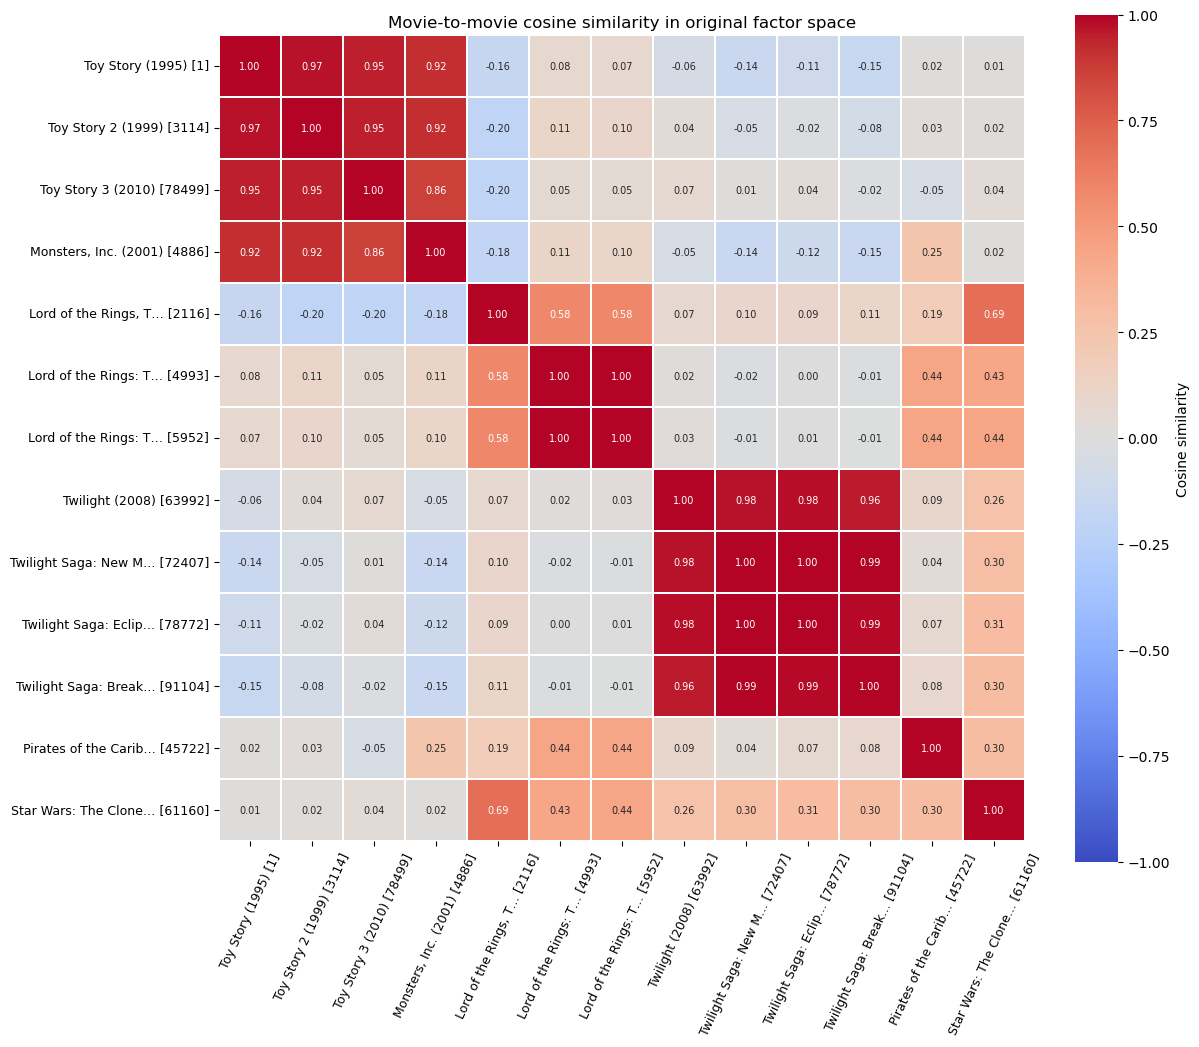

Saved cosine_similarity_ml-32m.pdf and cosine_similarity_ml-32m.png


In [5]:
MOVIE_GROUPS = {
    "Toy Story / animation": (1, 3114, 78499, 4886),
    "The Lord of the Rings": (2116, 4993, 5952),
    "Twilight": (63992, 72407, 78772, 91104),
    "Other films": (45722, 61160),
}

selected_by_group = {
    group: [m for m in ids if m in movie_to_index and valid_factors[movie_to_index[m]]]
    for group, ids in MOVIE_GROUPS.items()
}
selected_ids = [m for ids in selected_by_group.values() for m in ids]
selected_indices = np.array([movie_to_index[m] for m in selected_ids], dtype=int)
if len(selected_ids) < 3:
    raise ValueError("Fewer than three selected movies have valid factors.")


def short_title(movie_id: int, max_length: int = 28) -> str:
    title = movie_name(movie_id)
    return (title[:max_length - 1] + "…") if len(title) > max_length else title


def save_and_display(fig: plt.Figure, stem: str) -> None:
    """
    Save analysis figures separately from figures produced by main.py.
    """
    pdf_path = ANALYSIS_DIR / f"{stem}.pdf"
    fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
    fig.savefig(pdf_path.with_suffix(".png"), format="png", dpi=220, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    print(f"Saved {pdf_path.name} and {pdf_path.with_suffix('.png').name}")


selected_unit_vectors = unit_factors[selected_indices]
cosine_matrix = selected_unit_vectors @ selected_unit_vectors.T
heatmap_labels = [f"{short_title(m, 21)} [{m}]" for m in selected_ids]

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    cosine_matrix, xticklabels=heatmap_labels, yticklabels=heatmap_labels,
    cmap="coolwarm", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"fontsize": 7},
    square=True, linewidths=0.25, cbar_kws={"label": "Cosine similarity"}, ax=ax,
)
ax.set_title("Movie-to-movie cosine similarity in original factor space")
ax.tick_params(axis="x", rotation=65, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
save_and_display(fig, f"cosine_similarity_{DATASET_NAME}")

## 4. Two-dimensional embedding plots

### PCA — global linear projection

We fit PCA on **all nonzero movie embeddings**, then plot a manageable random background sample and label the selected movies. This differs from `utils.plot_embeddings()`, which fits its PCA on the *selected movies alone*. Fitting globally gives every highlighted movie coordinates in the same dataset-wide projection.

PCA preserves as much variation as possible among linear 2D projections, but 2D distances may still differ from distances in the original $K$-dimensional space.

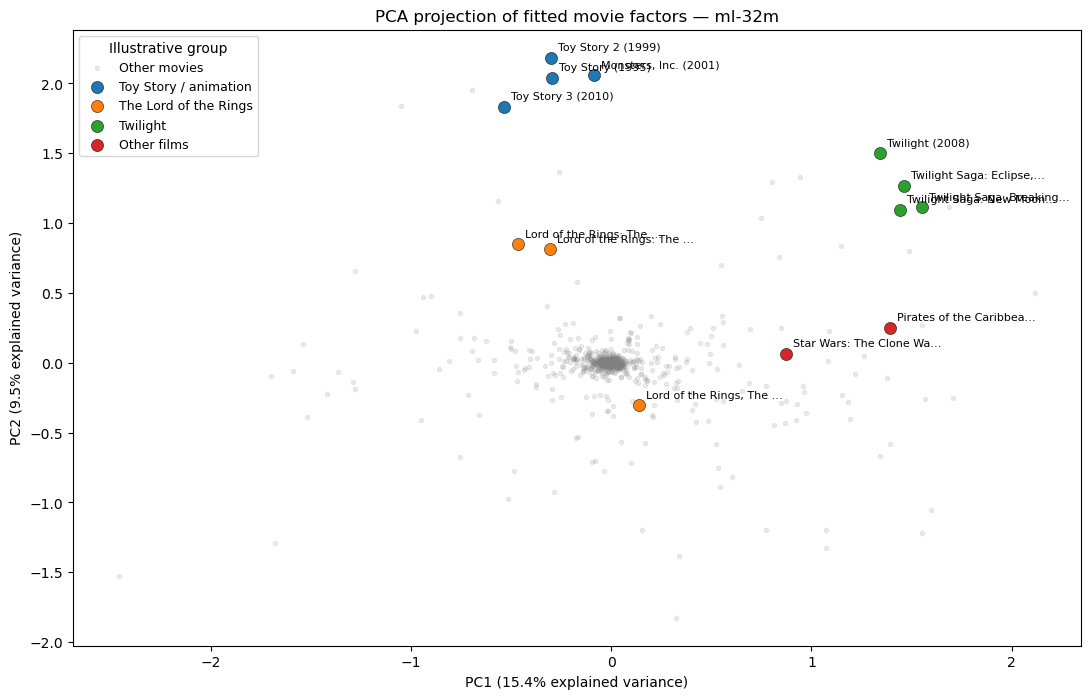

Saved movie_pca_ml-32m.pdf and movie_pca_ml-32m.png
Combined variance captured by the displayed PCs: 24.87%


In [6]:
rng = np.random.default_rng(SEED)
valid_indices = np.flatnonzero(valid_factors)
background = rng.choice(
    valid_indices, size=min(PCA_BACKGROUND, len(valid_indices)), replace=False
)

pca = PCA(n_components=2, random_state=SEED)
pca.fit(movie_factors[valid_factors])
pca_background = pca.transform(movie_factors[background])
pca_selected = pca.transform(movie_factors[selected_indices])


def draw_selected_projection(
    ax, selected_xy: np.ndarray, *, positions_by_index: dict[int, int] | None = None
) -> None:
    """
    Annotate the same preselected movie IDs on a 2D projection.
    """
    palette = dict(zip(MOVIE_GROUPS, sns.color_palette("tab10", n_colors=len(MOVIE_GROUPS))))
    for group, ids in selected_by_group.items():
        plot_xy, plot_ids = [], []
        for movie_id in ids:
            internal = movie_to_index[movie_id]
            if positions_by_index is None:
                xy = selected_xy[selected_ids.index(movie_id)]
            else:
                xy = selected_xy[positions_by_index[internal]]
            plot_xy.append(xy)
            plot_ids.append(movie_id)
        if not plot_ids:
            continue
        plot_xy = np.asarray(plot_xy)
        ax.scatter(plot_xy[:, 0], plot_xy[:, 1], s=76, color=palette[group],
                   edgecolors="black", linewidths=0.35, label=group, zorder=3)
        for (x, y), movie_id in zip(plot_xy, plot_ids):
            ax.annotate(short_title(movie_id, 24), (x, y), xytext=(5, 5),
                        textcoords="offset points", fontsize=8)
    ax.legend(title="Illustrative group", loc="best", fontsize=9)


fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(pca_background[:, 0], pca_background[:, 1], color="gray", alpha=0.15,
           s=9, label="Other movies")
draw_selected_projection(ax, pca_selected)
ax.set(
    xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.1f}% explained variance)",
    ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.1f}% explained variance)",
    title=f"PCA projection of fitted movie factors — {DATASET_NAME}",
)
save_and_display(fig, f"movie_pca_{DATASET_NAME}")
print("Combined variance captured by the displayed PCs:",
      f"{100 * pca.explained_variance_ratio_[:2].sum():.2f}%")

### t-SNE — local neighborhood visualization

To keep the notebook responsive, t-SNE is fitted on the **selected movies plus a seeded random sample of other movies**, not all MovieLens movies. The selected movies are *included in the fit*; they are not mapped afterward. t-SNE's distances and positions change with the sample and settings, so use this diagram as an exploratory view, **not** a quantitative similarity test.

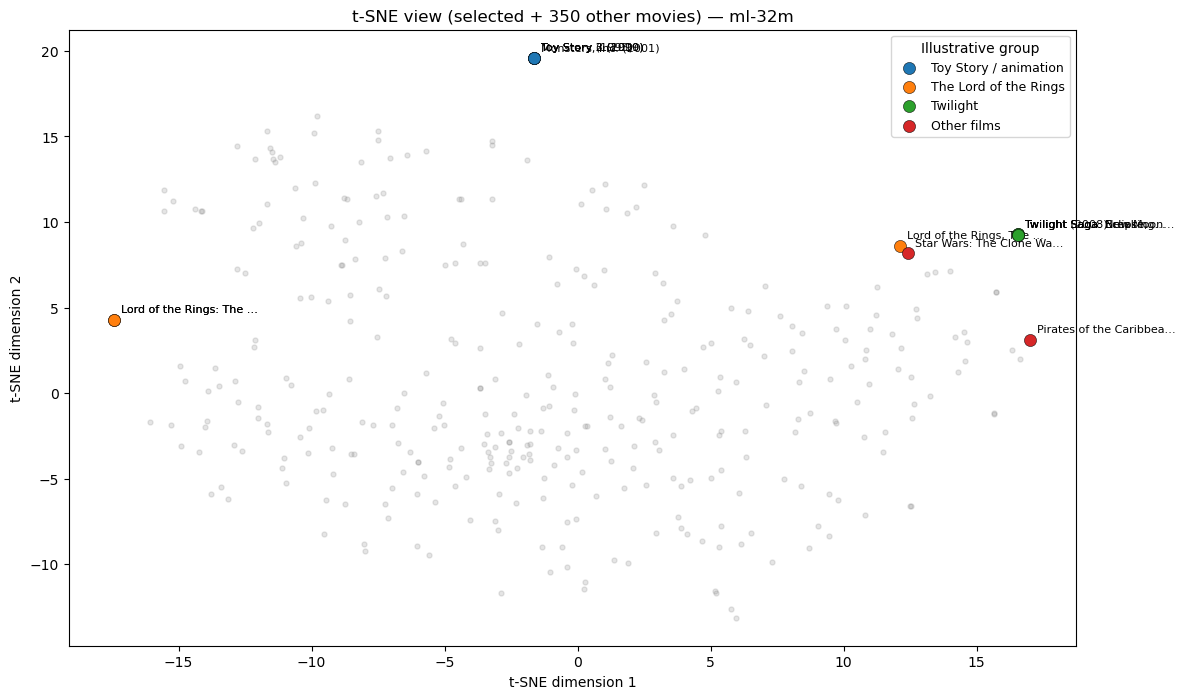

Saved movie_tsne_ml-32m.pdf and movie_tsne_ml-32m.png


In [7]:
other_indices = np.setdiff1d(valid_indices, selected_indices, assume_unique=False)
other_sample = rng.choice(
    other_indices, size=min(TSNE_BACKGROUND, len(other_indices)), replace=False
)
tsne_indices = np.concatenate([selected_indices, other_sample])
if len(tsne_indices) < 4:
    raise ValueError("Not enough valid movie embeddings for t-SNE.")

perplexity = min(30.0, max(2.0, (len(tsne_indices) - 1) / 4))
tsne = TSNE(n_components=2, perplexity=perplexity, init="pca",
            learning_rate="auto", random_state=SEED)
tsne_xy = tsne.fit_transform(movie_factors[tsne_indices])
local_position = {int(model_idx): pos for pos, model_idx in enumerate(tsne_indices)}

fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(tsne_xy[len(selected_indices):, 0], tsne_xy[len(selected_indices):, 1],
           color="gray", alpha=0.20, s=13)
draw_selected_projection(ax, tsne_xy, positions_by_index=local_position)
ax.set(xlabel="t-SNE dimension 1", ylabel="t-SNE dimension 2",
       title=f"t-SNE view (selected + {len(other_sample)} other movies) — {DATASET_NAME}")
save_and_display(fig, f"movie_tsne_{DATASET_NAME}")

## 5. New-user recommendations

`utils.recommend_movies_streamlit()` estimates the **new user's** bias and factor vector, keeping the trained movie parameters fixed. Its standard recommendation ranking score is:

$$s_{ui}=p_u^\top q_i+0.05 b_i.$$

This is a **ranking heuristic**, not the full fitted rating prediction $\hat r_{ui}=p_u^\top q_i+b_u+b_i$. The additive user bias is constant across candidate movies and does not change their order.

The Bias-Only baseline ranks movies using their learned item biases; updating the new user's scalar bias shifts predictions equally and **does not personalize the order**. We compare the two models using the same input ratings and exclude the rated movies.

In [8]:
# Edit this cell to explore different new users. These are ORIGINAL MovieLens IDs.
RATING_SCENARIOS = {
    "Toy Story / animation": {1: 5.0, 3114: 4.5, 4886: 4.5},
    "Lord of the Rings": {4993: 5.0, 5952: 5.0, 2116: 4.0},
    "Twilight": {63992: 5.0, 72407: 4.5, 78772: 4.0},
}
SELECTED_SCENARIO = "Toy Story / animation"
CUSTOM_RATINGS = {}  # e.g. {1: 5.0, 4993: 4.5}; overrides scenario if nonempty

user_ratings = dict(CUSTOM_RATINGS or RATING_SCENARIOS[SELECTED_SCENARIO])
if not user_ratings:
    raise ValueError("Rate at least one movie.")
for movie_id, rating in user_ratings.items():
    if movie_id not in movie_to_index:
        raise KeyError(f"Movie ID {movie_id} was not present in the trained model.")
    if not np.isfinite(rating) or not 0.5 <= rating <= 5.0:
        raise ValueError(f"Movie {movie_id}: rating must be between 0.5 and 5.0.")

display(Markdown("**Input ratings for the new user**"))
display(pd.DataFrame([
    {"MovieLens ID": movie_id, "Title": movie_name(movie_id), "Rating": rating}
    for movie_id, rating in user_ratings.items()
]))

**Input ratings for the new user**

,MovieLens ID,Title,Rating
0,1,Toy Story (1995),5.0
1,3114,Toy Story 2 (1999),4.5
2,4886,"Monsters, Inc. (2001)",4.5


In [9]:
if factor_summary is None:
    raise FileNotFoundError(
        "Missing training_summary_bias_factors.json: run main.py to train the "
        "Matrix Factorization model and save its hyperparameters."
    )

factor_params = factor_summary["hyperparameters"]
required = ("lambda_reg", "gamma", "tau")
if any(name not in factor_params for name in required):
    raise ValueError("Factor training summary has incomplete hyperparameters.")

movie_ids = list(user_ratings)
ratings = list(user_ratings.values())

factor_recommendations = utils.recommend_movies_streamlit(
    base_path=str(DATA_DIR),
    experiment_path=str(EXPERIMENT_DIR),
    dataset_name=DATASET_NAME,
    movie_ids=movie_ids,
    movie_ratings=ratings,
    top_n=TOP_N,
    lambda_reg=factor_params["lambda_reg"],
    gamma=factor_params["gamma"],
    tau=factor_params["tau"],
)

# Ranking by fitted movie biases, with already-rated movies excluded.
# Equivalent to adding any constant new-user bias to every candidate.
bias_recommendations = None
if bias_movie_factors is not None:
    scores = bias_movie_factors.copy()
    scores[[movie_to_index[m] for m in movie_ids]] = -np.inf
    baseline_indices = np.argsort(scores)[-min(TOP_N, n_movies-len(movie_ids)):][::-1]
    bias_recommendations = [movie_name(int(index_to_movie[int(i)])) for i in baseline_indices]

result_rows = []
for i in range(len(factor_recommendations)):
    result_rows.append({
        "Rank": i + 1,
        "Bias + Factors": factor_recommendations[i],
        "Bias-Only": bias_recommendations[i] if bias_recommendations else "—",
    })

display(pd.DataFrame(result_rows))
if bias_recommendations is None:
    print("Bias-Only model not saved; train it with --model both to compare.")

,Rank,Bias + Factors,Bias-Only
0,1,Toy Story 3 (2010),Black Harvest (1992)
1,2,Finding Nemo (2003),Wesley (2009)
2,3,Beauty and the Beast (1991),WWE: The Triumph and Tragedy of World Class Ch...
3,4,WALL·E (2008),SpongeBob SquarePants: Tide and Seek
4,5,"Incredibles, The (2004)",Evening's Civil Twilight in Empires of Tin (2008)
5,6,Aladdin (1992),Visions of Frank (2007)
6,7,Up (2009),Anybody's Son Will Do
7,8,Inside Out (2015),The Viking (1931)
8,9,Ratatouille (2007),The Revolutionary (2011)
9,10,"Lion King, The (1994)",Jeff Ross Roasts the Border (2017)


## 6. How much does movie-bias weighting affect the ranking?

To inspect the classroom heuristic rather than simply accept `0.05`, we estimate the new user's factor and bias using the *same five alternating closed-form updates as* `utils._recommend_factor_titles()`. We then hold the estimate fixed and compare rankings for different item-bias weights. The changed weights are **only used for recommendation ranking**, never for the training objective or RMSE.

In [10]:
def estimate_new_user_parameters(rated: dict[int, float]):
    """
    Replicate the new-user closed-form updates from utils for analysis only.
    """
    indices = np.array([movie_to_index[m] for m in rated], dtype=int)
    observed = np.asarray(list(rated.values()), dtype=float)
    e = movie_factors[indices]
    b = movie_biases[indices]
    lam = float(factor_params["lambda_reg"])
    gamma = float(factor_params["gamma"])
    tau = float(factor_params["tau"])
    system = lam * (e.T @ e) + tau * np.eye(n_factors)
    p_user = np.zeros(n_factors)
    b_user = 0.0
    for _ in range(5):
        p_user = np.linalg.solve(system, lam * (e.T @ (observed - b - b_user)))
        b_user = lam * np.sum(observed - e @ p_user - b) / (lam * len(indices) + gamma)
    return p_user, b_user, indices


def recommendations_at_weight(rated: dict[int, float], weight: float, top_n: int = TOP_N):
    p_user, b_user, rated_indices = estimate_new_user_parameters(rated)
    factor_scores = movie_factors @ p_user
    total = factor_scores + weight * movie_biases
    total[rated_indices] = -np.inf
    winners = np.argsort(total)[-min(top_n, n_movies - len(rated_indices)):][::-1]
    return pd.DataFrame([
        {
            "Rank": j,
            "MovieLens ID": int(index_to_movie[int(i)]),
            "Title": movie_name(int(index_to_movie[int(i)])),
            "Factor contribution": round(float(factor_scores[i]), 4),
            "Weighted movie bias": round(float(weight * movie_biases[i]), 4),
            "Ranking score": round(float(total[i]), 4),
        }
        for j, i in enumerate(winners, 1)
    ])


# Sanity check: the analysis implementation must agree with utils at the default weight.
default_weight = utils.DEFAULT_BIAS_WEIGHT
reference_ranking = recommendations_at_weight(user_ratings, default_weight)
if reference_ranking["Title"].tolist() != factor_recommendations:
    raise AssertionError(
        "Analysis scoring differs from utils.recommend_movies_streamlit(). "
        "Check that both use the same fitted parameters and five update steps."
    )
print(f"Validated against utils at movie-bias weight {default_weight}.")

for weight in (0.0, default_weight, 1.0):
    display(Markdown(f"**Movie-bias ranking weight = {weight:.2f}**"))
    display(recommendations_at_weight(user_ratings, weight)[
        ["Rank", "Title", "Factor contribution", "Weighted movie bias", "Ranking score"]
    ])

Validated against utils at movie-bias weight 0.05.


**Movie-bias ranking weight = 0.00**

,Rank,Title,Factor contribution,Weighted movie bias,Ranking score
0,1,Toy Story 3 (2010),1.5128,0.0,1.5128
1,2,Finding Nemo (2003),1.3936,0.0,1.3936
2,3,Beauty and the Beast (1991),1.3711,-0.0,1.3711
3,4,WALL·E (2008),1.3437,0.0,1.3437
4,5,"Incredibles, The (2004)",1.3436,0.0,1.3436
5,6,Aladdin (1992),1.3385,0.0,1.3385
6,7,Up (2009),1.2841,0.0,1.2841
7,8,Inside Out (2015),1.2632,0.0,1.2632
8,9,"Lion King, The (1994)",1.2162,0.0,1.2162
9,10,Ratatouille (2007),1.2108,0.0,1.2108


**Movie-bias ranking weight = 0.05**

,Rank,Title,Factor contribution,Weighted movie bias,Ranking score
0,1,Toy Story 3 (2010),1.5128,0.0090,1.5218
1,2,Finding Nemo (2003),1.3936,0.0132,1.4068
2,3,Beauty and the Beast (1991),1.3711,-0.0033,1.3678
3,4,WALL·E (2008),1.3437,0.0174,1.3611
4,5,"Incredibles, The (2004)",1.3436,0.0142,1.3577
5,6,Aladdin (1992),1.3385,0.0008,1.3393
6,7,Up (2009),1.2841,0.0160,1.3002
7,8,Inside Out (2015),1.2632,0.0104,1.2737
8,9,Ratatouille (2007),1.2108,0.0128,1.2235
9,10,"Lion King, The (1994)",1.2162,0.0069,1.2232


**Movie-bias ranking weight = 1.00**

,Rank,Title,Factor contribution,Weighted movie bias,Ranking score
0,1,Destination: Pluto Beyond the Flyby (2016),0.0003,3.3285,3.3287
1,2,Wesley (2009),-0.0003,3.1790,3.1787
2,3,SpongeBob SquarePants: Tide and Seek,0.0008,3.1197,3.1205
3,4,WWE: The Triumph and Tragedy of World Class Ch...,0.0008,3.1197,3.1205
4,5,Black Harvest (1992),-0.0003,3.1062,3.1059
5,6,The Sound of Violet (2022),-0.0005,2.9529,2.9524
6,7,Jeff Ross Roasts the Border (2017),-0.0001,2.8476,2.8475
7,8,The Thorn (1971),-0.0002,2.8304,2.8302
8,9,A Dramatic Film (2019),0.0003,2.8150,2.8153
9,10,Crazy Bible (2018),-0.0003,2.6959,2.6957


## 7. Rating-sensitivity check

The Bias-Only ordering remains the same when a new user changes the numerical values of their ratings, provided the set of already-rated movies stays the same. The factor model can produce a different ordering because the user's fitted factor vector changes. The following cell measures the overlap rather than assuming a specific outcome.

In [11]:
revised_ratings = {movie_id: (0.5 if rating >= 3.0 else 5.0)
                   for movie_id, rating in user_ratings.items()}
original_top = reference_ranking["Title"].tolist()
revised_top = recommendations_at_weight(revised_ratings, default_weight)["Title"].tolist()
shared = len(set(original_top) & set(revised_top))

print("Original top-N vs. changed-ratings top-N")
print(f"Common movies: {shared}/{min(len(original_top), len(revised_top))}")
display(pd.DataFrame({
    "Rank": range(1, min(len(original_top), len(revised_top)) + 1),
    "Original ratings": original_top[:len(revised_top)],
    "Changed ratings": revised_top[:len(original_top)],
}))
print("Bias-Only ranking is unchanged by these rating values (same rated IDs excluded).")

Original top-N vs. changed-ratings top-N
Common movies: 0/10


,Rank,Original ratings,Changed ratings
0,1,Toy Story 3 (2010),Destination: Pluto Beyond the Flyby (2016)
1,2,Finding Nemo (2003),Wesley (2009)
2,3,Beauty and the Beast (1991),WWE: The Triumph and Tragedy of World Class Ch...
3,4,WALL·E (2008),SpongeBob SquarePants: Tide and Seek
4,5,"Incredibles, The (2004)",Black Harvest (1992)
5,6,Aladdin (1992),The Sound of Violet (2022)
6,7,Up (2009),Jeff Ross Roasts the Border (2017)
7,8,Inside Out (2015),The Thorn (1971)
8,9,Ratatouille (2007),A Dramatic Film (2019)
9,10,"Lion King, The (1994)",Crazy Bible (2018)


Bias-Only ranking is unchanged by these rating values (same rated IDs excluded).
